In [3]:
import sys
sys.path.append("..")          
import numpy as np
import pandas as pd
import matplotlib.pyplot as pt
import seaborn as sn
from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_iterative_imputer  
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from xgboost import XGBClassifier
from src.transformers import IQRClipper

Defaulting to user installation because normal site-packages is not writeable
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\Youcode\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## preparation des donnees

In [4]:
data = pd.read_csv("../data/orig/student_mental_health.csv")

cible = "Mental_Health_Risk"
quant_discretes = ["Age", "Year_of_Study"]
quant_continues = ["Sleep_Hours", "Study_Hours_Per_Week", "GPA",
                   "Social_Media_Hours", "Screen_Time_Hours",
                   "Financial_Stress", "Family_Support", "Attendance_Rate"]
qualitatives = ["Gender", "Physical_Activity", "Part_Time_Job",
                "Diet_Quality", "Previous_Mental_Health_History"]

ordreRisque = {"Low": 0, "Medium": 1, "High": 2}
labelsRisque = list(ordreRisque)


## qualite de data 

In [5]:
colonnesTexte = [c for c in data.columns if pd.api.types.is_string_dtype(data[c])]
espaces = sum((data[c].dropna() != data[c].dropna().str.strip()).sum() for c in colonnesTexte)

print("Lignes dupliquées :", data.duplicated().sum())
print("Student_ID dupliqués :", data["Student_ID"].duplicated().sum())
print("Cible manquante :", data["Mental_Health_Risk"].isnull().sum())
print("Valeurs texte avec espaces parasites :", espaces)

plagesValides = {"Age": (16, 40), "Year_of_Study": (1, 5), "Sleep_Hours": (2, 12),
                 "Study_Hours_Per_Week": (0, 80), "GPA": (0, 4),
                 "Social_Media_Hours": (0, 16), "Screen_Time_Hours": (0, 18),
                 "Financial_Stress": (1, 10), "Family_Support": (1, 10),
                 "Attendance_Rate": (0, 100)}

horsPlage = {col: int((data[col].notna() & data[col].between(bas, haut)).sum())
             for col, (bas, haut) in plagesValides.items()}
horsPlage

Lignes dupliquées : 0
Student_ID dupliqués : 0
Cible manquante : 0
Valeurs texte avec espaces parasites : 0


{'Age': 2000,
 'Year_of_Study': 2000,
 'Sleep_Hours': 1938,
 'Study_Hours_Per_Week': 2000,
 'GPA': 1962,
 'Social_Media_Hours': 1942,
 'Screen_Time_Hours': 2000,
 'Financial_Stress': 1909,
 'Family_Support': 1946,
 'Attendance_Rate': 1953}

In [6]:
X = data.drop(columns=["Student_ID", cible])
y = data[cible].map(ordreRisque)                   

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train :", X_train.shape, " Test :", X_test.shape)

Train : (1600, 15)  Test : (400, 15)


In [7]:
repartitionClasses = pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),}).round(3)
repartitionClasses.index = labelsRisque
repartitionClasses

,train,test
Low,0.33,0.33
Medium,0.33,0.33
High,0.34,0.34


###  Traitement des valeurs manquantes

In [8]:
valeursManquantes = X_train.isnull().sum()
valeursManquantes[valeursManquantes > 0].sort_values(ascending=False)

Financial_Stress      71
Diet_Quality          53
Sleep_Hours           49
Social_Media_Hours    49
Family_Support        40
Attendance_Rate       34
GPA                   27
dtype: int64

In [9]:

colonnesIteratives = ["GPA", "Social_Media_Hours", "Screen_Time_Hours",
                      "Study_Hours_Per_Week", "Year_of_Study"]

colonnesMediane = ["Sleep_Hours", "Financial_Stress", "Family_Support",
                   "Attendance_Rate", "Age"]



imputation = ColumnTransformer(
    transformers=[
        ("iteratif", IterativeImputer(max_iter=10, random_state=42), colonnesIteratives),
        ("mediane", SimpleImputer(strategy="median"), colonnesMediane),
    ],remainder="passthrough",verbose_feature_names_out=False,  
)

print(data.isna().sum())

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64


###  traitement des valeurs aberrantes 

In [10]:
lignes = []
for col in quant_continues:
    s = X_train[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    masque = (s < inf) | (s > sup)
    lignes.append({"variable": col, "Inf": round(inf, 2), "Sup": round(sup, 2),
                   "nbrAberrantes": int(masque.sum()), "pourcentage": round(masque.mean() * 100, 2)})

tableauAberrantes = pd.DataFrame(lignes)
tableauAberrantes

,variable,Inf,Sup,nbrAberrantes,pourcentage
0,Sleep_Hours,3.75,9.75,8,0.52
1,Study_Hours_Per_Week,3.60,36.40,4,0.25
2,GPA,1.64,3.48,6,0.38
3,Social_Media_Hours,3.12,8.93,17,1.10
4,Screen_Time_Hours,3.95,13.15,6,0.38
5,Financial_Stress,0.00,12.00,0,0.00
6,Family_Support,1.00,12.20,0,0.00
7,Attendance_Rate,66.25,104.25,8,0.51


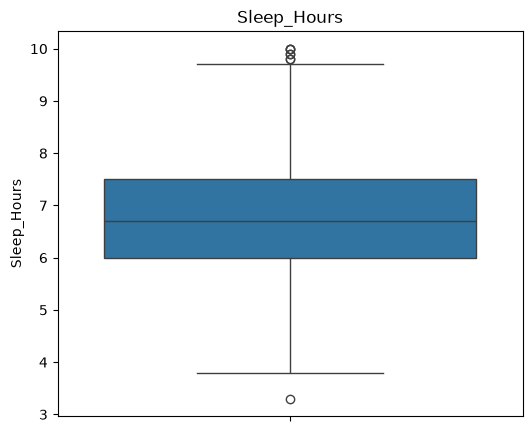

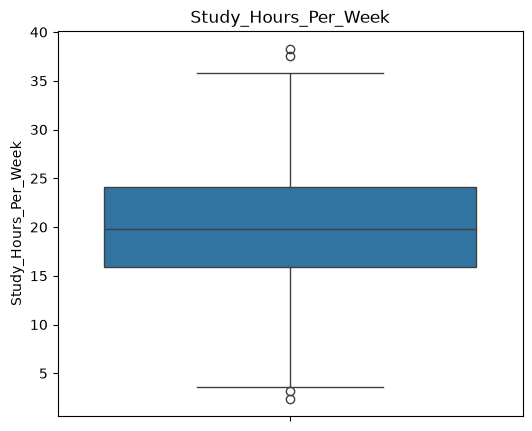

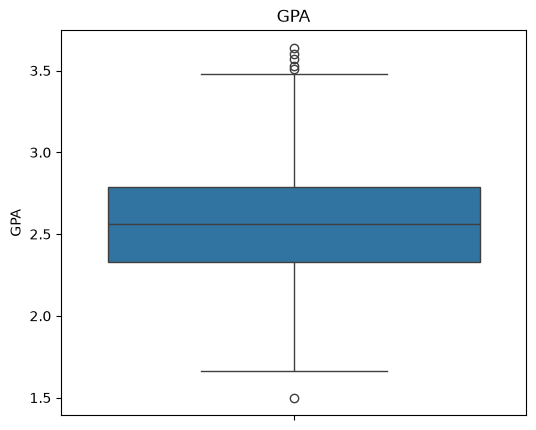

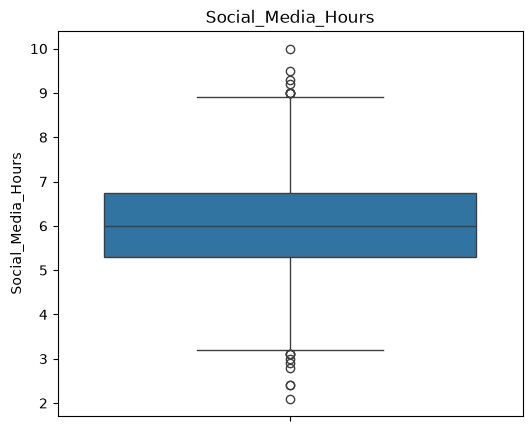

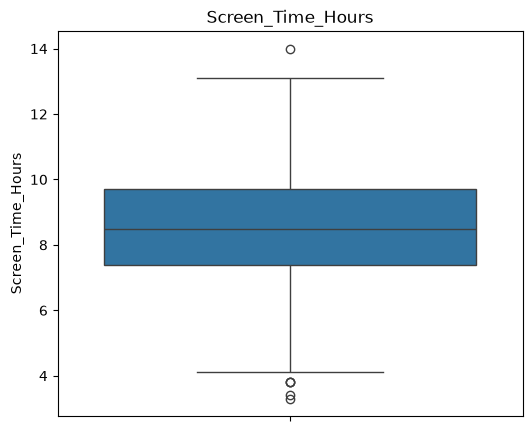

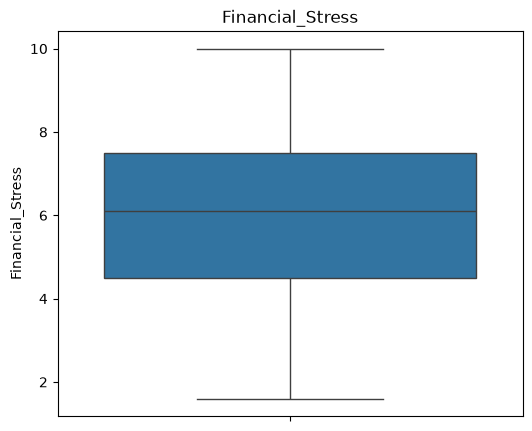

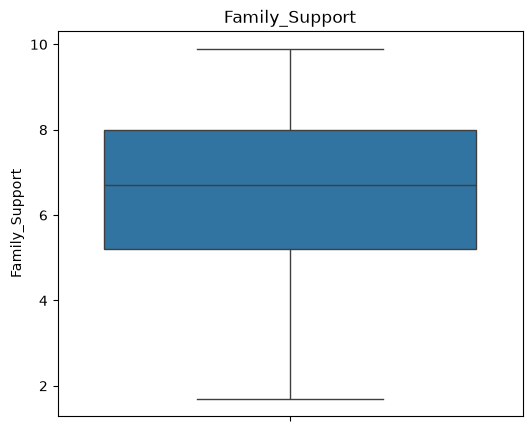

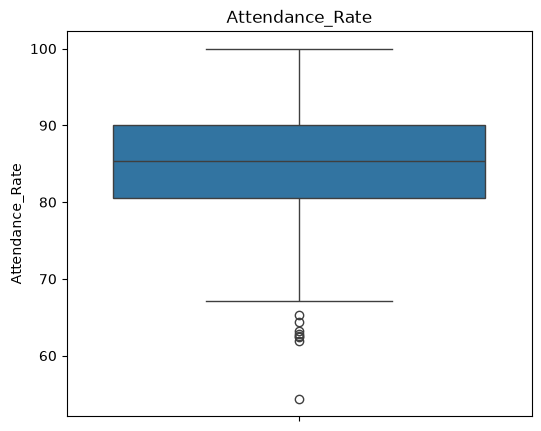

In [12]:
for col in quant_continues:
    pt.figure(figsize=(6, 5))
    sn.boxplot(y=X_train[col])
    pt.title(col)
    pt.show()

### Encodage des variables categorielles

In [13]:
colonnesOrdinales = ["Physical_Activity", "Diet_Quality"]
colonnesNominales = [c for c in qualitatives if c not in colonnesOrdinales]


pipelineNominal = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

ordreOrdinal = [["Low", "Moderate", "High"],        
                ["Poor", "Average", "Good"]]       

pipelineOrdinal = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OrdinalEncoder(categories=ordreOrdinal,
                                handle_unknown="use_encoded_value", unknown_value=-1)),
])

### Gestion du desequilibre des classes

In [14]:
repartitionClasses = pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
}).round(3)
repartitionClasses.index = labelsRisque
repartitionClasses

,train,test
Low,0.33,0.33
Medium,0.33,0.33
High,0.34,0.34


pas de SMOTE. Les classes sont équilibrées dans le train 


### standardisation des variables numériques

In [15]:
pipelineContinues = Pipeline([
    ("clipping", IQRClipper(factor=1.5)),           
    ("standardisation", StandardScaler()),
])

transformation = ColumnTransformer(
    transformers=[
        ("continues", pipelineContinues, quant_continues),
        ("discretes", StandardScaler(), quant_discretes),
        ("nominal", pipelineNominal, colonnesNominales),
        ("ordinal", pipelineOrdinal, colonnesOrdinales),
    ],
    remainder="drop",
)

### Regroupement dans un Pipeline 

In [16]:
pretraitement = Pipeline([
    ("imputation", imputation),
    ("transformation", transformation),
]).set_output(transform="pandas")       

XTrainPrepare = pretraitement.fit_transform(X_train)   
XTestPrepare = pretraitement.transform(X_test)        

print("Train :", XTrainPrepare.shape, " manquants :", XTrainPrepare.isna().sum().sum())
print("Test  :", XTestPrepare.shape, " manquants :", XTestPrepare.isna().sum().sum())
XTrainPrepare.head()


Train : (1600, 19)  manquants : 0
Test  : (400, 19)  manquants : 0


,continues__Sleep_Hours,continues__Study_Hours_Per_Week,continues__GPA,continues__Social_Media_Hours,continues__Screen_Time_Hours,continues__Financial_Stress,continues__Family_Support,continues__Attendance_Rate,discretes__Age,discretes__Year_of_Study,nominal__Gender_Female,nominal__Gender_Male,nominal__Gender_Non-binary,nominal__Part_Time_Job_No,nominal__Part_Time_Job_Yes,nominal__Previous_Mental_Health_History_No,nominal__Previous_Mental_Health_History_Yes,ordinal__Physical_Activity,ordinal__Diet_Quality
521,-0.041768,-1.464070,-0.851885,-0.091913,-0.090513,-0.259617,-0.021546,-0.529229,0.416561,-1.224199,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
1393,1.231159,-1.377690,-1.696815,-0.718194,-0.393108,0.657234,-1.233064,-1.180699,-0.058152,-1.224199,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
1710,-0.496385,0.729989,-0.338892,0.087024,0.635713,0.225775,0.694351,1.569952,0.891274,1.058690,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,2.0
555,0.412849,-0.116538,-0.248364,0.355430,-0.211551,-0.637144,-0.627305,-0.920111,-0.532865,-0.463236,0.0,1.0,0.0,0.0,1.0,1.0,0.0,2.0,1.0
523,-0.314538,0.142603,-1.213998,-0.360319,-0.029995,1.304423,1.189972,-2.671841,0.416561,1.058690,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,2.0


In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

## Entrainement


###  Modeles

In [18]:
modeles = {
    "L.Regression": LogisticRegression(max_iter=2000),
    "R.N.C": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(eval_metric="mlogloss", random_state=42),
}

# Chaque modèle reçoit sa propre copie du prétraitement
pipelines = {
    nom: Pipeline([("pretraitement", clone(pretraitement)), ("modele", modele)])
    for nom, modele in modeles.items()
}

### validation croisee (5 )

In [19]:
validationCroisee = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

predictions = {}
for nom, pipe in pipelines.items():
    # le prétraitement est ré-appris à chaque pli : pas de data leakage
    probabilites = cross_val_predict(pipe, X_train, y_train, cv=validationCroisee, method="predict_proba")
    predictions[nom] = {"proba": probabilites, "classe": probabilites.argmax(axis=1)}

print("Prédictions calculées pour :", list(predictions))

Prédictions calculées pour : ['L.Regression', 'R.N.C', 'XGBoost']


### Metriques 

In [20]:
lignes = []
for nom, p in predictions.items():
    lignes.append({
        "modele": nom,
        "accuracy": accuracy_score(y_train, p["classe"]),
        "precision": precision_score(y_train, p["classe"], average="macro"),
        "recall": recall_score(y_train, p["classe"], average="macro"),
        "f1": f1_score(y_train, p["classe"], average="macro"),
        "roc_auc": roc_auc_score(y_train, p["proba"], multi_class="ovr", average="macro"),
    })

tableauMetriques = pd.DataFrame(lignes).set_index("modele").round(3)
tableauMetriques

,accuracy,precision,recall,f1,roc_auc
modele,,,,,
L.Regression,0.758,0.757,0.757,0.757,0.907
R.N.C,0.706,0.700,0.705,0.702,0.859
XGBoost,0.689,0.688,0.689,0.688,0.860


*Précision, rappel et F1 sont des moyennes **macro** : les 3 classes comptent de la même façon. Le ROC-AUC est calculé en one-vs-rest.*

In [21]:
# Détail par classe (précision, rappel, F1 pour Low, Medium et High)
for nom, p in predictions.items():
    print(f"===== {nom} =====")
    print(classification_report(y_train, p["classe"], target_names=labelsRisque, digits=3))

===== L.Regression =====
              precision    recall  f1-score   support

         Low      0.819     0.816     0.818       528
      Medium      0.638     0.638     0.638       528
        High      0.813     0.816     0.815       544

    accuracy                          0.757      1600
   macro avg      0.757     0.757     0.757      1600
weighted avg      0.758     0.757     0.758      1600

===== R.N.C =====
              precision    recall  f1-score   support

         Low      0.762     0.790     0.776       528
      Medium      0.588     0.538     0.562       528
        High      0.751     0.787     0.768       544

    accuracy                          0.706      1600
   macro avg      0.700     0.705     0.702      1600
weighted avg      0.701     0.706     0.703      1600

===== XGBoost =====
              precision    recall  f1-score   support

         Low      0.749     0.750     0.749       528
      Medium      0.555     0.545     0.550       528
        High

### Matrice de confusion chaque modele 

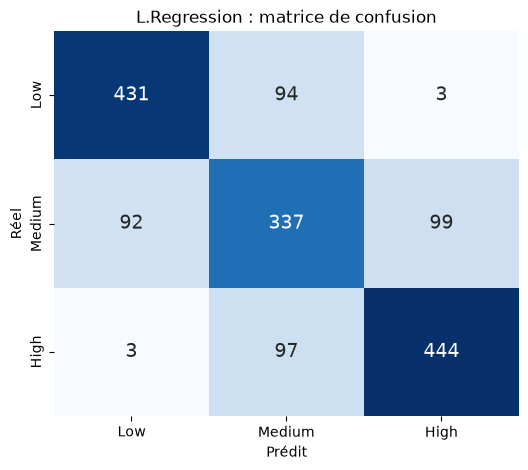

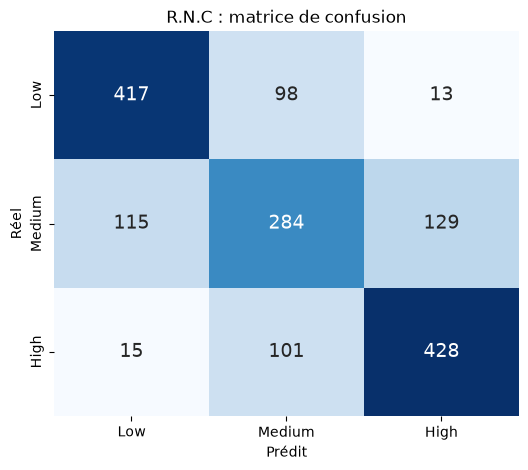

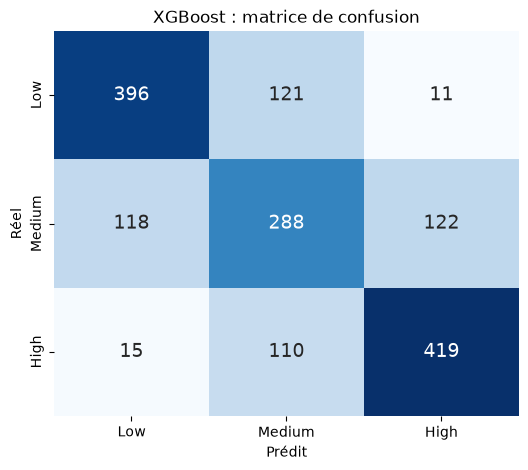

In [22]:
for nom, p in predictions.items():
    matrice = confusion_matrix(y_train, p["classe"])

    pt.figure(figsize=(6, 5))
    sn.heatmap(matrice, annot=True, fmt="d", cmap="Blues", annot_kws={"size": 14},
               xticklabels=labelsRisque, yticklabels=labelsRisque, cbar=False)
    pt.title(f"{nom} : matrice de confusion")
    pt.xlabel("Prédit")
    pt.ylabel("Réel")
    pt.show()

### Courbes ROC et AUC

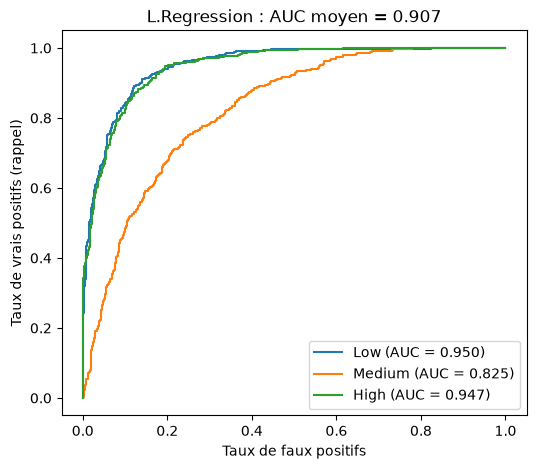

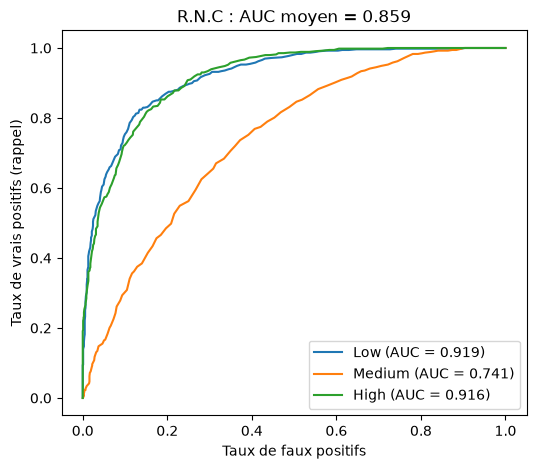

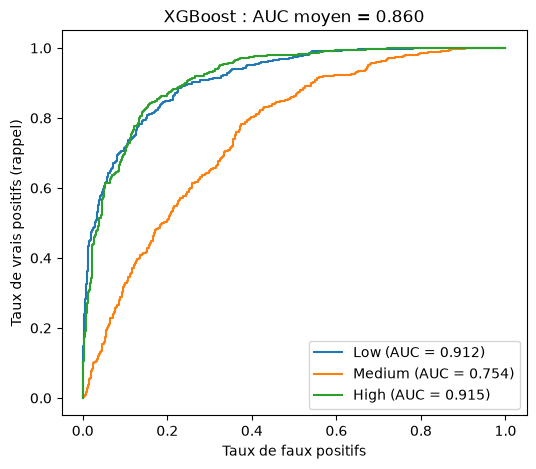

In [24]:
yBinaire = label_binarize(y_train, classes=[0, 1, 2])       # une colonne par classe (one-vs-rest)

for nom, p in predictions.items():
    pt.figure(figsize=(6, 5))
    for i, classe in enumerate(labelsRisque):
        fpr, tpr, _ = roc_curve(yBinaire[:, i], p["proba"][:, i])
        auc = roc_auc_score(yBinaire[:, i], p["proba"][:, i])
        pt.plot(fpr, tpr, label=f"{classe} (AUC = {auc:.3f})")

    
    pt.title(f"{nom} : AUC moyen = {tableauMetriques.loc[nom, 'roc_auc']:.3f}")
    pt.xlabel("Taux de faux positifs")
    pt.ylabel("Taux de vrais positifs (rappel)")
    pt.legend(loc="lower right")
    pt.show()

### Entrainement final sur tout le train

In [27]:
resume = []
for nom, pipe in pipelines.items():
    pipe.fit(X_train, y_train)                                   # entraînement sur tout le train
    resume.append({
        "modele": nom,
        "accuracy train": round(pipe.score(X_train, y_train), 3),
        "accuracy validation croisée": tableauMetriques.loc[nom, "accuracy"],
    })

resume = pd.DataFrame(resume).set_index("modele")
resume["ecart"] = (resume["accuracy train"] - resume["accuracy validation croisée"]).round(3)
resume

,accuracy train,accuracy validation croisée,ecart
modele,,,
L.Regression,0.767,0.758,0.009
R.N.C,1.000,0.706,0.294
XGBoost,1.000,0.689,0.311


### Conclusion de l'étape 3
- **Meilleur modèle (avant optimisation) :** LogisticRegression (F1 0,757 ; ROC-AUC 0,907). RandomForest (0,702) et XGBoost (0,688) sont plus faibles.
- **Classe la plus difficile à prédire :** Medium (F1 le plus bas pour les trois modèles).
- **Surapprentissage :** fort pour RandomForest et XGBoost (accuracy train = 1,000 contre 0,706 et 0,689 en validation croisée), absent pour LogisticRegression (écart 0,009).
- **Étape suivante :** régulariser les modèles à base d'arbres et affiner la régression logistique (étape 4).

    ### optimization des models

In [28]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

nomLogistique, nomForet, nomXGBoost = list(pipelines)      # noms des trois modèles (même ordre qu'à l'étape 3)

## optimizer le logitic regression

In [ ]:

grilleLogistique = {"modele__C": [0.01, 0.1, 1, 10, 100]}

rechercheLogistique = GridSearchCV(
    pipelines[nomLogistique], grilleLogistique,
    cv=validationCroisee, scoring="f1_macro",
)
rechercheLogistique.fit(X_train, y_train)

print("Meilleurs parametres :", rechercheLogistique.best_params_)
print("Meilleur F1 (validation croisée) :", round(rechercheLogistique.best_score_, 3))


Meilleurs parametres : {'modele__C': 100}
Meilleur F1 (validation croisée) : 0.758


## optimizer Random forest

In [36]:
distributionsForet = {
    "modele__n_estimators": [100, 200, 300],
    "modele__max_depth": [3, 5, 8, 12, None],
    "modele__min_samples_leaf": [1, 3, 5, 10],
    "modele__max_features": ["sqrt", "log2", 0.5],
}

rechercheForet = RandomizedSearchCV(
    pipelines[nomForet], distributionsForet, n_iter=15,
    cv=validationCroisee, scoring="f1_macro", random_state=42,
)
rechercheForet.fit(X_train, y_train)

print("Meilleurs paramètres :", rechercheForet.best_params_)
print("Meilleur F1 (validation croisée) :", round(rechercheForet.best_score_, 3))


Meilleurs paramètres : {'modele__n_estimators': 200, 'modele__min_samples_leaf': 1, 'modele__max_features': 'sqrt', 'modele__max_depth': None}
Meilleur F1 (validation croisée) : 0.702


### RandomizedSearchCV : XGBoost

In [37]:

distributionsXGBoost = {
    "modele__n_estimators": [100, 200, 300],
    "modele__max_depth": [2, 3, 4, 6],
    "modele__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "modele__subsample": [0.7, 0.85, 1.0],
    "modele__colsample_bytree": [0.7, 0.85, 1.0],
}

rechercheXGBoost = RandomizedSearchCV(
    pipelines[nomXGBoost], distributionsXGBoost, n_iter=20,
    cv=validationCroisee, scoring="f1_macro", random_state=42,
)
rechercheXGBoost.fit(X_train, y_train)

print("Meilleurs paramètres :", rechercheXGBoost.best_params_)
print("Meilleur F1 (validation croisée) :", round(rechercheXGBoost.best_score_, 3))


Meilleurs paramètres : {'modele__subsample': 0.7, 'modele__n_estimators': 300, 'modele__max_depth': 3, 'modele__learning_rate': 0.05, 'modele__colsample_bytree': 0.85}
Meilleur F1 (validation croisée) : 0.724


## comparaison entre les trois models

In [41]:
modelesOptimises = {
    nomLogistique: rechercheLogistique.best_estimator_,
    nomForet: rechercheForet.best_estimator_,
    nomXGBoost: rechercheXGBoost.best_estimator_,
}

# Mêmes métriques qu'en 3.3, calculées sur les prédictions par validation croisée
predictionsOptimisees = {}
lignes = []
for nom, pipe in modelesOptimises.items():
    probabilites = cross_val_predict(pipe, X_train, y_train, cv=validationCroisee, method="predict_proba")
    classes = probabilites.argmax(axis=1)
    predictionsOptimisees[nom] = {"proba": probabilites, "classe": classes}
    lignes.append({
        "modele": nom,
        "accuracy": accuracy_score(y_train, classes),
        "precision": precision_score(y_train, classes, average="macro"),
        "recall": recall_score(y_train, classes, average="macro"),
        "f1": f1_score(y_train, classes, average="macro"),
        "roc_auc": roc_auc_score(y_train, probabilites, multi_class="ovr", average="macro"),
    })

tableauOptimise = pd.DataFrame(lignes).set_index("modele").round(3)

comparaison = pd.concat([tableauMetriques.assign(version="1 avant"),
                         tableauOptimise.assign(version="2 après")])
comparaison = comparaison.reset_index().set_index(["modele", "version"]).sort_index()
comparaison

accuracy  precision  recall     f1  roc_auc
modele       version                                             
L.Regression 1 avant     0.758      0.757   0.757  0.757    0.907
             2 après     0.759      0.758   0.758  0.758    0.907
R.N.C        1 avant     0.706      0.700   0.705  0.702    0.859
             2 après     0.706      0.700   0.705  0.702    0.859
XGBoost      1 avant     0.689      0.688   0.689  0.688    0.860
             2 après     0.727      0.723   0.726  0.724    0.881

## Choix du modele selon le metrics

In [51]:

choix = tableauOptimise[["accuracy"]].copy()
choix["recall High"] = {nom: recall_score(y_train, p["classe"], average=None)[2]      
                        for nom, p in predictionsOptimisees.items()}
choix["ecart"] = {nom: modelesOptimises[nom].score(X_train, y_train) - tableauOptimise.loc[nom, "accuracy"]
                  for nom in modelesOptimises}
choix = choix.round(3)

meilleurNom = choix["accuracy"].idxmax()
print("Modèle retenu :", meilleurNom)



Modèle retenu : L.Regression


### Évaluation du Logistic Regre sur Test

In [52]:
meilleurModele = modelesOptimises[meilleurNom]          # déjà entraîné sur tout le train (refit)

probabilitesTest = meilleurModele.predict_proba(X_test)
classesTest = probabilitesTest.argmax(axis=1)

resultatTest = pd.Series({
    "accuracy": accuracy_score(y_test, classesTest),
    "precision": precision_score(y_test, classesTest, average="macro"),
    "recall": recall_score(y_test, classesTest, average="macro"),
    "f1": f1_score(y_test, classesTest, average="macro"),
    "roc_auc": roc_auc_score(y_test, probabilitesTest, multi_class="ovr", average="macro"),
}).round(3)

print(f"{meilleurNom} sur le test (validation croisée : F1 = {tableauOptimise.loc[meilleurNom, 'f1']})")
print(resultatTest.to_string())
print()
print(classification_report(y_test, classesTest, target_names=labelsRisque, digits=3))

L.Regression sur le test (validation croisée : F1 = 0.758)
accuracy     0.762
precision    0.765
recall       0.762
f1           0.763
roc_auc      0.917

              precision    recall  f1-score   support

         Low      0.824     0.780     0.802       132
      Medium      0.638     0.667     0.652       132
        High      0.832     0.838     0.835       136

    accuracy                          0.762       400
   macro avg      0.765     0.762     0.763       400
weighted avg      0.765     0.762     0.764       400



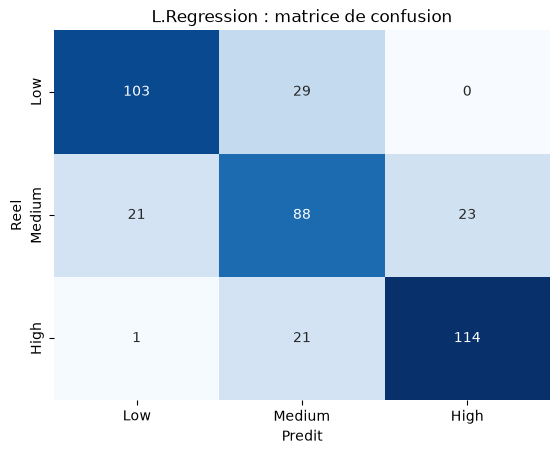

In [54]:
matriceTest = confusion_matrix(y_test, classesTest)
sn.heatmap(matriceTest, annot=True, fmt="d", cmap="Blues",
           xticklabels=labelsRisque, yticklabels=labelsRisque, cbar=False)
pt.title(f"{meilleurNom} : matrice de confusion")
pt.xlabel("Predit")
pt.ylabel("Reel")
pt.show()

Analyse des erreurs de prédiction et limites du modèle